In [12]:
import os

print("Current Directory:", os.getcwd())

print("\nFiles in Current Directory:")
print(os.listdir())

Current Directory: C:\Users\DELL\Downloads

Files in Current Directory:
['.ipynb_checkpoints', '25BD1A05H2 (1).txt', '25bd1a05h2.js', '25BD1A05H2.txt', '25BD1A05H2_join corealted query.txt', '25bd1a05h3 (1).js', '25bd1a05h3 (2).js', '25bd1a05h3.js', '44 A SEND.txt', '44 send ans.txt', '5t - see this....wait ra mak inka em pettale.. (5).respond with smtg', '5t - see this....wait ra mak inka em pettale...respond with smtg', '5t-ANSWERS (1).txt', '5t-ANSWERS (2).txt', '5t-ANSWERS.txt', '5t-keep answers fasttttt.txt', 'A.class', 'AP PPT.pdf', 'arduino-1.6.12-windows.exe', 'ArduinoAppLab_0.8.0_Windows_x86-64_installer.exe', 'Arrow Slide Puzzle Installer.exe', 'B.class', 'CH34x_Install_Windows_v3_4.zip', 'ChatGPT Installer (1).exe', 'ChatGPT Installer.exe', 'ChromeSetup (1).exe', 'ChromeSetup.exe', 'composer-2026-03-18_15-06.qasm', 'CoolTermWin64Bit.zip', 'data.csv', 'Data.java', 'Day 1 12_08_2026-Polynomial-20260917T132559Z-1-001.zip', 'DAY1-12-08-2026.zip', 'Day2-14-08-2026.zip', 'Day5.ipy

In [13]:
import pandas as pd

df = pd.read_csv("students_dropout_academic_success .csv")

print("Dataset loaded successfully!")

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset loaded successfully!

First 5 rows:
   Marital Status  Application mode  Application order  Course  \
0               1                17                  5     171   
1               1                15                  1    9254   
2               1                 1                  5    9070   
3               1                17                  2    9773   
4               2                39                  1    8014   

   Daytime/evening attendance  Previous qualification  \
0                           1                       1   
1                           1                       1   
2                           1                       1   
3                           1                       1   
4                           0                       1   

   Previous qualification (grade)  Nacionality  Mother's qualification  \
0                           122.0            1                      19   
1                           160.0            1                      

In [14]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Check target distribution
print("\nTarget Distribution:")
print(df['target'].value_counts())

# Display statistical information
print("\nStatistical Description:")
print(df.describe())

Missing Values:
Marital Status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                              

In [15]:
# Separate target column
y = df['target']

# Remove target column from input features
X = df.drop('target', axis=1)

# Remove semester performance information
# because this model predicts at admission time

semester_columns = [
    col for col in X.columns
    if col.startswith("Curricular units")
]

X = X.drop(columns=semester_columns)

print("Input Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

print("\nTotal input features:", X.shape[1])

Input Features:
['Marital Status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Unemployment rate', 'Inflation rate', 'GDP']

Target:
0     Dropout
1    Graduate
2     Dropout
3    Graduate
4    Graduate
Name: target, dtype: str

Total input features: 24


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:")
print(y_train.value_counts())

print("\nTesting Target:")
print(y_test.value_counts())

Training Data: (3539, 24)
Testing Data: (885, 24)
Training Target:
target
Graduate    1767
Dropout     1137
Enrolled     635
Name: count, dtype: int64

Testing Target:
target
Graduate    442
Dropout     284
Enrolled    159
Name: count, dtype: int64


In [17]:
# Create Decision Tree model
dt_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=6,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree Model Training Completed!")

Decision Tree Model Training Completed!


Decision Tree Accuracy: 56.158192090395474 %

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.60      0.60      0.60       284
    Enrolled       0.28      0.38      0.33       159
    Graduate       0.69      0.60      0.64       442

    accuracy                           0.56       885
   macro avg       0.52      0.53      0.52       885
weighted avg       0.59      0.56      0.57       885



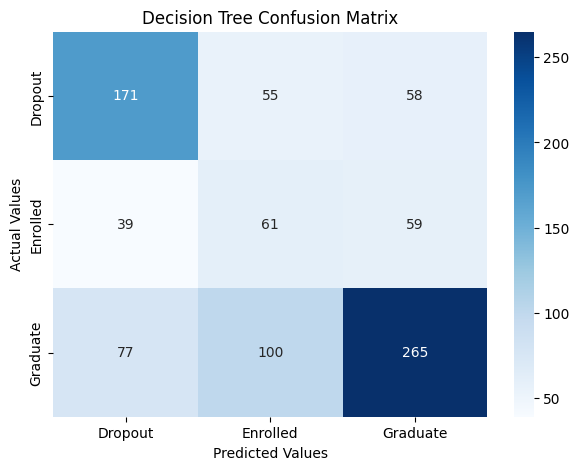

In [18]:
# Predict test data
dt_predictions = dt_model.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:",
      dt_accuracy * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, dt_predictions))

# Confusion Matrix
dt_cm = confusion_matrix(
    y_test,
    dt_predictions,
    labels=dt_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [19]:
# Create Random Forest model
rf_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        criterion='gini',
        max_depth=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


Random Forest Accuracy: 58.19209039548022 %

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.62      0.60      0.61       284
    Enrolled       0.31      0.47      0.38       159
    Graduate       0.72      0.61      0.66       442

    accuracy                           0.58       885
   macro avg       0.55      0.56      0.55       885
weighted avg       0.62      0.58      0.59       885



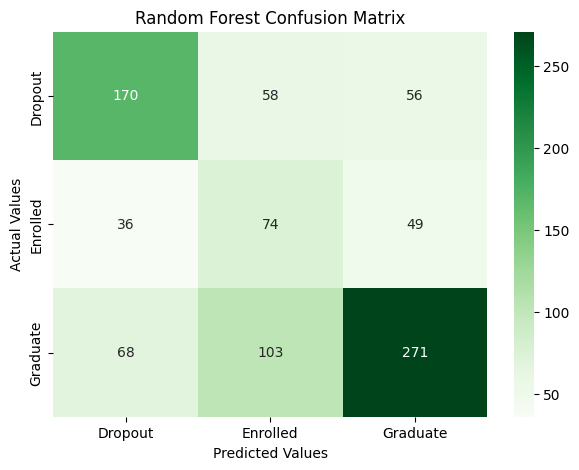

In [20]:
# Predict test data
rf_predictions = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:",
      rf_accuracy * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

# Confusion Matrix
rf_cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=rf_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [21]:
# Calculate evaluation metrics

models = ['Decision Tree', 'Random Forest']

accuracies = [
    accuracy_score(y_test, dt_predictions),
    accuracy_score(y_test, rf_predictions)
]

precisions = [
    precision_score(
        y_test, dt_predictions,
        average='macro', zero_division=0
    ),
    precision_score(
        y_test, rf_predictions,
        average='macro', zero_division=0
    )
]

recalls = [
    recall_score(
        y_test, dt_predictions,
        average='macro', zero_division=0
    ),
    recall_score(
        y_test, rf_predictions,
        average='macro', zero_division=0
    )
]

f1_scores = [
    f1_score(
        y_test, dt_predictions,
        average='macro', zero_division=0
    ),
    f1_score(
        y_test, rf_predictions,
        average='macro', zero_division=0
    )
]

# Create comparison table

results = pd.DataFrame({
    'Model': models,
    'Accuracy': accuracies,
    'Precision': precisions,
    'Recall': recalls,
    'F1 Score': f1_scores
})

print(results)

           Model  Accuracy  Precision    Recall  F1 Score
0  Decision Tree  0.561582   0.523981  0.528436  0.522495
1  Random Forest  0.581921   0.552025  0.559041  0.549182


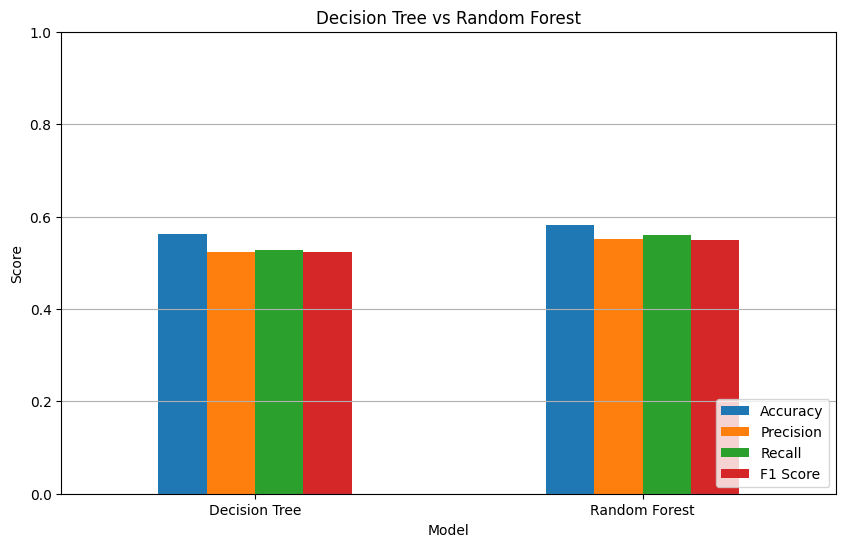

In [22]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()

                           Feature  Importance
16         Tuition fees up to date    0.132053
19               Age at enrollment    0.094109
12                 Admission grade    0.077328
6   Previous qualification (grade)    0.071316
3                           Course    0.068302
18              Scholarship holder    0.067609
10             Mother's occupation    0.057875
11             Father's occupation    0.055447
1                 Application mode    0.054624
23                             GDP    0.044282
21               Unemployment rate    0.040410
8           Mother's qualification    0.032218
15                          Debtor    0.032034
22                  Inflation rate    0.031374
9           Father's qualification    0.029782


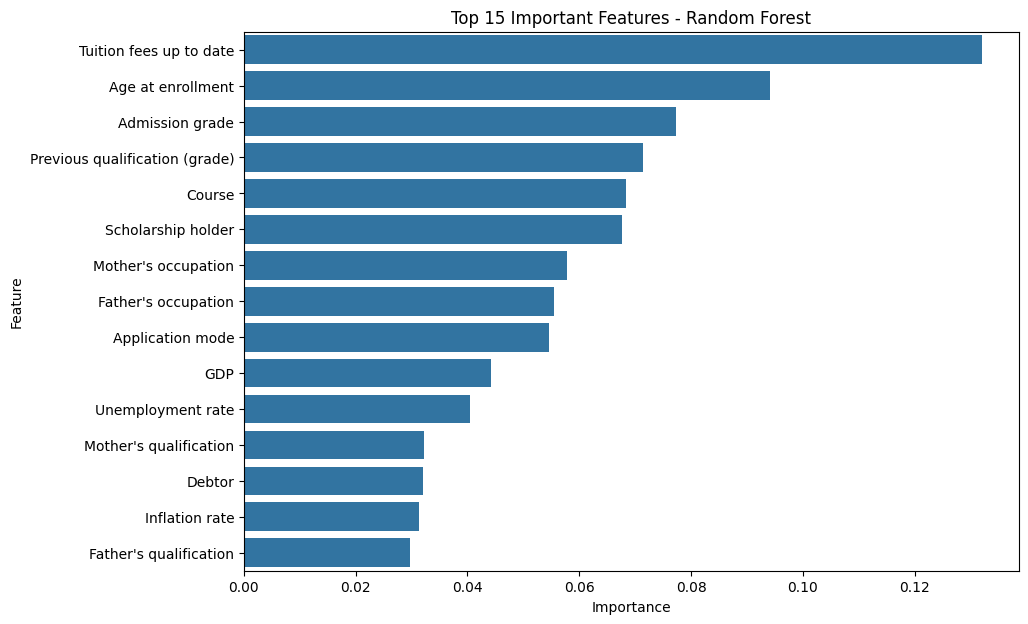

In [23]:
# Get trained Random Forest classifier
rf_classifier = rf_model.named_steps['classifier']

# Get feature importance
importance = rf_classifier.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance
})

# Sort in descending order
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15))

# Visualize top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features - Random Forest")
plt.show()

In [30]:
def risk_category(probability):

    if probability >= 0.70:
        return "High Risk"

    elif probability >= 0.40:
        return "Medium Risk"

    else:
        return "Low Risk"


risk_df['Risk Level'] = risk_df['Dropout Risk (%)'].apply(
    lambda x: risk_category(x / 100)
)

print(risk_df.head(20))

# Save results
risk_df.to_csv("student_dropout_risk_results.csv")

print("Student risk report saved successfully!")

NameError: name 'risk_df' is not defined

In [31]:
import joblib

# Save Decision Tree
joblib.dump(dt_model, "decision_tree_model.pkl")

# Save Random Forest
joblib.dump(rf_model, "random_forest_model.pkl")

print("Both models saved successfully!")

Both models saved successfully!
